# MAE 6246 — Week 10: A beam controller in MuJoCo
**Linear Systems and Control · October 30, 2026**

Apply the course's linear state-feedback controller and angle-only observer to a nonlinear physics engine. Compare it with the linear plant using the **same gains, sampling, initial condition, and torque limit**. The animation shows actual and estimated mass positions on both systems.

Run all cells in order. The notebook is self-contained: no repository files are needed. The first cell installs missing dependencies. Numerical checks and plots run without graphics; video generation also needs an OpenGL/EGL graphics context. On Colab, the notebook selects EGL before importing MuJoCo.

1. Build the beam and sliding mass.
2. Apply the sampled controller and observer.
3. Compare the nonlinear and linear responses.
4. Check the model and numerical accuracy.
5. Animate actual and estimated positions.

The orange sphere represents a **sliding point mass**, consistent with the course model. This is not a rolling-ball or contact simulation.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"mujoco": "mujoco==3.17.0", "numpy": "numpy", "scipy": "scipy",
            "matplotlib": "matplotlib", "PIL": "pillow", "imageio_ffmpeg": "imageio-ffmpeg"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Dependencies ready.")

Dependencies ready.


## 1. Physical model and linear design
Use $x=[d,\dot{d},\theta,\dot{\theta}]^T$, with mass $m=1\,\mathrm{kg}$, beam/drive inertia $I=2\,\mathrm{kg}\,\mathrm{m}^2$, and gravity $g=9.81\,\mathrm{m}/\mathrm{s}^2$. Positive $\theta$ raises the right-hand end of the beam.

The linear model at the centered, horizontal equilibrium is

$$
\ddot{d}=-g\theta,\qquad I\ddot{\theta}=-mgd+u,\qquad y=\theta.
$$

The MuJoCo model has a hinge for the beam and a slide joint for the mass. A unit-gear motor applies torque $u$ at the hinge. The engine integrates the nonlinear motion; we do not prescribe the beam angle or mass position during the simulation.

For checking the engine, the corresponding nonlinear equations are

$$
\ddot{d}=d\dot{\theta}^{2}-g\sin\theta,\qquad
(I+\varepsilon_I+md^2)\ddot{\theta}
=u-mgd\cos\theta-2md\dot{d}\dot{\theta}.
$$

Here $\varepsilon_I=10^{-8}\,\mathrm{kg}\,\mathrm{m}^2$ is a tiny positive rotational inertia used to approximate a point mass in MuJoCo. The ball graphic is offset above the beam, while its inertial center follows the centerline. Geometry does not determine the explicitly specified inertias. Collisions, friction, and end stops are disabled; the baseline stays on the drawn beam.

Keep the controller poles at $-1,-1.5,-2,-2.5$ and observer poles at $-3,-4,-5,-6$.

In [2]:
from pathlib import Path
import argparse
import json
import os
import sys

# Colab/Linux headless rendering. Set before importing MuJoCo.
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import mujoco
import numpy as np
from scipy.linalg import expm
from scipy.signal import place_poles

MASS, INERTIA, GRAVITY = 1.0, 2.0, 9.81
# MuJoCo requires a positive rotational inertia. Its effect is negligible here.
SLIDER_INERTIA = 1e-8
A = np.array([[0, 1, 0, 0], [0, 0, -GRAVITY, 0],
              [0, 0, 0, 1], [-MASS*GRAVITY/INERTIA, 0, 0, 0.]])
B = np.array([[0.], [0.], [0.], [1/INERTIA]])
C = np.array([[0., 0., 1., 0.]])
K = place_poles(A, B, [-1, -1.5, -2, -2.5]).gain_matrix
L = place_poles(A.T, C.T, [-3, -4, -5, -6]).gain_matrix.T
X0 = np.array([0.08, 0., np.deg2rad(2.), 0.])

MODEL_XML = f'''<mujoco model="Observer-controlled mass on a beam">
  <compiler angle="radian" inertiafromgeom="false"/>
  <option timestep="0.001" gravity="0 0 -{GRAVITY}" integrator="RK4"/>
  <visual>
    <global offwidth="720" offheight="360"/>
    <quality shadowsize="2048"/>
    <headlight ambient="0.55 0.55 0.55" diffuse="0.65 0.65 0.65" specular="0.1 0.1 0.1"/>
    <rgba haze="0.96 0.97 0.99 1"/>
  </visual>
  <default>
    <joint damping="0" frictionloss="0" armature="0" limited="false"/>
    <geom contype="0" conaffinity="0"/>
  </default>
  <asset>
    <texture name="sky" type="skybox" builtin="gradient"
             rgb1="0.96 0.97 0.99" rgb2="0.96 0.97 0.99" width="256" height="256"/>
  </asset>
  <worldbody>
    <light pos="0 -1 2" dir="0 0 -1" diffuse="0.8 0.8 0.8"/>
    <geom name="floor" type="plane" size="2 2 0.01" rgba="0.89 0.91 0.94 1"/>
    <geom name="base" type="box" pos="0 0 0.025" size="0.09 0.065 0.025" rgba="0.3 0.36 0.43 1"/>
    <geom name="stand" type="cylinder" pos="0 0 0.14" size="0.018 0.09" rgba="0.42 0.48 0.55 1"/>
    <body name="beam" pos="0 0 0.25">
      <!-- A positive angle raises the right-hand end of the beam. -->
      <joint name="beam_hinge" type="hinge" axis="0 -1 0"/>
      <!-- Specified beam/drive inertia; visual dimensions do not set inertia. -->
      <inertial pos="0 0 0" mass="10" diaginertia="0.02 {INERTIA} {INERTIA}"/>
      <geom name="beam_shape" type="box" size="0.4 0.023 0.012" rgba="0.26 0.34 0.44 1"/>
      <geom name="pivot" type="sphere" size="0.018" rgba="0.25 0.3 0.37 1"/>
      <body name="slider">
        <joint name="mass_slide" type="slide" axis="1 0 0"/>
        <inertial pos="0 0 0" mass="{MASS}"
                  diaginertia="{SLIDER_INERTIA} {SLIDER_INERTIA} {SLIDER_INERTIA}"/>
        <!-- The sphere is a visual marker above the track; the point-mass
             dynamics act on the beam centerline, with no rolling/contact. -->
        <geom name="ball" type="sphere" pos="0 0 0.035" size="0.023" rgba="0.95 0.48 0.12 1"/>
      </body>
    </body>
  </worldbody>
  <actuator><motor name="torque" joint="beam_hinge" gear="1"/></actuator>
  <sensor><jointpos name="angle" joint="beam_hinge"/></sensor>
</mujoco>'''

In [3]:
def new_model(physics_dt=0.001):
    model = mujoco.MjModel.from_xml_string(MODEL_XML)
    model.opt.timestep = physics_dt
    return model, mujoco.MjData(model)


def set_state(model, data, x):
    data.joint("mass_slide").qpos[0] = x[0]
    data.joint("mass_slide").qvel[0] = x[1]
    data.joint("beam_hinge").qpos[0] = x[2]
    data.joint("beam_hinge").qvel[0] = x[3]
    mujoco.mj_forward(model, data)


def read_state(data):
    return np.array([data.joint("mass_slide").qpos[0],
                     data.joint("mass_slide").qvel[0],
                     data.joint("beam_hinge").qpos[0],
                     data.joint("beam_hinge").qvel[0]])


def zero_order_hold(a, b, dt):
    """Exact discretization of xdot=a*x+b*u with held input."""
    n, m = b.shape
    augmented = np.zeros((n+m, n+m))
    augmented[:n, :n], augmented[:n, n:] = a, b
    discrete = expm(augmented*dt)
    return discrete[:n, :n], discrete[:n, n:]

## 2. The controller and observer
For each plant, use

$$
u=\operatorname{clip}(-K\hat{x},-10,10),\qquad
\dot{\hat{x}}=A\hat{x}+Bu+L(y-C\hat{x}).
$$

Only the current beam angle and applied torque enter the observer. The actual state is recorded for comparison; it is not used in observer-based feedback.

The control period is 2 ms. At each sample, compute the torque from the current estimate, measure the angle, and hold both while advancing the observer. The observer and linear plant use exact zero-order-hold updates. MuJoCo advances with two 1 ms RK4 steps under the same held torque. Thus both systems use the same digital implementation. This differs slightly from the continuously updated feedback in the earlier linear notebook.

For a full-state baseline, `feedback="state"` uses $u=-Kx$ instead. The default is `feedback="observer"`.

The optional `torque_limit`, `control_dt`, and `physics_dt` arguments make saturation and sample-rate experiments possible. Keep the control period an integer multiple of the physics step.

In [4]:
def simulate(plant="mujoco", *, x0=X0, duration=12., control_dt=0.002,
             physics_dt=0.001, torque_limit=10., feedback="observer"):
    """Use identical sampling, gains, saturation and observer on either plant.

    The observer uses only the current angle and the actual applied torque.
    Measurements and control are held during each observer update. True state
    enters feedback only when feedback='state', for the baseline check.
    """
    if plant not in ("mujoco", "linear") or feedback not in ("observer", "state"):
        raise ValueError("Invalid plant or feedback choice")
    if min(control_dt, physics_dt, duration, torque_limit) <= 0:
        raise ValueError("Timesteps, duration and torque limit must be positive")
    substeps = int(round(control_dt/physics_dt))
    steps = int(round(duration/control_dt))
    if substeps < 1 or not np.isclose(substeps*physics_dt, control_dt):
        raise ValueError("control_dt must be an integer multiple of physics_dt")
    if not np.isclose(steps*control_dt, duration):
        raise ValueError("duration must be an integer multiple of control_dt")
    times = np.arange(steps+1)*control_dt
    x = np.array(x0, dtype=float).copy()
    xhat = np.zeros(4)
    X, Xhat = np.empty((steps+1, 4)), np.empty((steps+1, 4))
    U = np.empty(steps+1)
    Ad, Bd = zero_order_hold(A, B, control_dt)
    Ao, Bo = zero_order_hold(A-L@C, np.column_stack([B, L]), control_dt)
    if plant == "mujoco":
        model, data = new_model(physics_dt)
        set_state(model, data, x)
    for j in range(steps+1):
        if plant == "mujoco":
            x = read_state(data)
        y = float((C@x).item())  # Only the measured angle is supplied to the observer.
        state_for_control = xhat if feedback == "observer" else x
        u = float(np.clip(-(K@state_for_control).item(), -torque_limit, torque_limit))
        X[j], Xhat[j], U[j] = x, xhat, u
        if j == steps:
            break
        next_estimate = Ao@xhat + Bo@np.array([u, y])
        if plant == "mujoco":
            data.ctrl[0] = u
            for _ in range(substeps):
                mujoco.mj_step(model, data)
        else:
            x = Ad@x + Bd[:, 0]*u
        xhat = next_estimate
    if not np.isfinite(X).all() or not np.isfinite(Xhat).all():
        raise RuntimeError("Non-finite simulated trajectory")
    return dict(t=times, x=X, xhat=Xhat, u=U, plant=plant,
                control_dt=control_dt, physics_dt=physics_dt,
                torque_limit=torque_limit, feedback=feedback)

## 3. Compare the responses
Start both plants at $d(0)=8$ cm and $\theta(0)=2^\circ$, with zero velocities. Initialize both observers at $\hat{x}(0)=0$.

Each plant has its own copy of the same observer/controller. Once their outputs differ, their estimated states and torques can differ too. This is a comparison of two closed-loop systems, rather than a comparison under one precomputed input.

In [5]:
def compare(mj, linear):
    delta = mj["x"]-linear["x"]
    return {"max_position_difference_mm": float(1000*np.max(np.abs(delta[:, 0]))),
            "max_angle_difference_deg": float(np.rad2deg(np.max(np.abs(delta[:, 2])))),
            "final_position_mm": float(1000*mj["x"][-1, 0]),
            "final_position_error_mm": float(1000*(mj["x"][-1, 0]-mj["xhat"][-1, 0])),
            "peak_torque_Nm": float(np.max(np.abs(mj["u"])))}


def plot_comparison(mj, linear):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
    scale = [100, 100, 180/np.pi, 180/np.pi]
    labels = ["Mass position [cm]", "Mass velocity [cm/s]",
              "Beam angle [deg]", "Angular velocity [deg/s]"]
    for j, ax in enumerate(axes[:2].flat):
        ax.plot(mj["t"], mj["x"][:, j]*scale[j], color="#d18736", label="MuJoCo actual", lw=2)
        ax.plot(mj["t"], mj["xhat"][:, j]*scale[j], "--", color="#0072B2", label="MuJoCo observer")
        ax.plot(linear["t"], linear["x"][:, j]*scale[j], ":", color="#222222", label="Linear actual")
        ax.plot(linear["t"], linear["xhat"][:, j]*scale[j], "-.", color="#7a5195", alpha=.65,
                label="Linear observer")
        ax.set_ylabel(labels[j])
    for r, color in [(mj, "#d18736"), (linear, "#222222")]:
        style = "-" if r is mj else ":"
        axes[2, 0].plot(r["t"], 100*(r["x"][:, 0]-r["xhat"][:, 0]), style,
                        color=color, label=r["plant"])
        axes[2, 1].plot(r["t"], r["u"], style, color=color, label=r["plant"])
    axes[2, 0].set_ylabel("Position estimation error [cm]")
    axes[2, 1].set_ylabel("Applied torque [N m]")
    for ax in axes.flat:
        ax.grid(alpha=.2)
        ax.set_xlabel("Time [s]")
    axes[0, 0].legend(fontsize=8)
    axes[2, 1].legend()
    fig.suptitle("Same angle-only observer and controller: MuJoCo vs. linear plant")
    fig.tight_layout()
    return fig

MuJoCo version: 3.17.0
K = [[-11.33905199  -3.92456677  35.5         14.        ]]
L = [-69.72477064 -83.20449541  18.         119.        ]


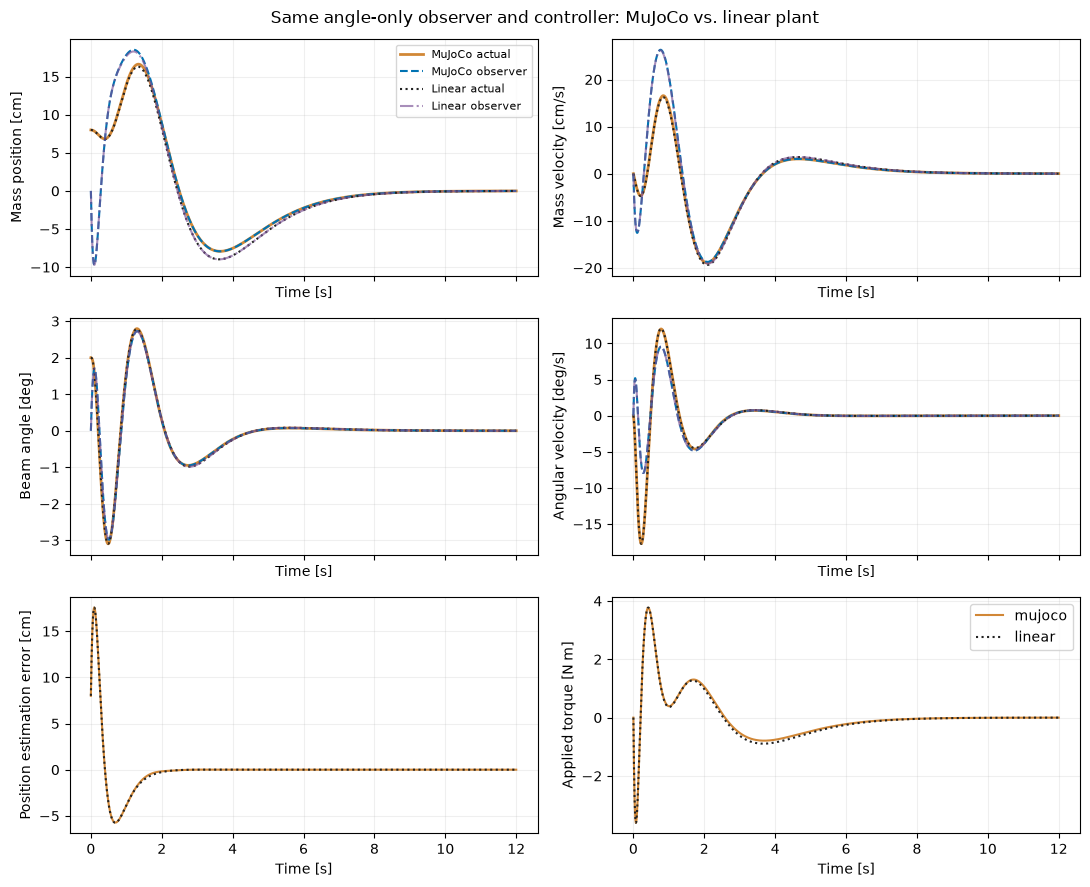

{
  "max_position_difference_mm": 10.898402560197779,
  "max_angle_difference_deg": 0.048681355976358545,
  "final_position_mm": -0.05763868666448708,
  "final_position_error_mm": 6.548644404263964e-05,
  "peak_torque_Nm": 3.7693534545194627
}


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML

mj_result = simulate("mujoco")
linear_result = simulate("linear")
print("MuJoCo version:", mujoco.__version__)
print("K =", K)
print("L =", L.ravel())
comparison_figure = plot_comparison(mj_result, linear_result)
plt.show()
print(json.dumps(compare(mj_result, linear_result), indent=2))

## 4. Validate the physics and comparison
The following checks establish that:

- The centered, horizontal configuration is an equilibrium.
- Finite differences of MuJoCo's accelerations reproduce the course's $A,B$ matrices, up to the tiny slider inertia.
- Nonlinear engine accelerations match the equations above at nonzero states.
- The sampled linear closed loop has eigenvalues strictly inside the unit circle.
- Halving only the physics step leaves the response unchanged to the stated tolerance.
- Ten-times-smaller initial disturbances produce much closer agreement.
- Both full-state feedback and observer feedback regulate the system.

The tolerances below apply to the baseline parameters and initial condition. If you change the experiment, inspect the results and reconsider the assertions instead of treating them as universal stability guarantees.

In [7]:
def engine_rhs(model, data, x, u):
    set_state(model, data, x)
    data.ctrl[0] = u
    mujoco.mj_forward(model, data)
    return np.array([x[1], data.joint("mass_slide").qacc[0],
                     x[3], data.joint("beam_hinge").qacc[0]])


def validate_model():
    """Check the engine's equilibrium, linearization and nonlinear accelerations."""
    model, data = new_model()
    eps, origin = 1e-6, np.zeros(4)
    np.testing.assert_allclose(engine_rhs(model, data, origin, 0), 0, atol=1e-12)
    Ae = np.column_stack([(engine_rhs(model, data, origin+eps*v, 0)
                         -engine_rhs(model, data, origin-eps*v, 0))/(2*eps)
                         for v in np.eye(4)])
    Be = ((engine_rhs(model, data, origin, eps)
          -engine_rhs(model, data, origin, -eps))/(2*eps))[:, None]
    np.testing.assert_allclose(Ae, A, atol=5e-8, rtol=0)
    np.testing.assert_allclose(Be, B, atol=5e-9, rtol=0)
    for x, u in [(np.array([.1, .2, .15, -.3]), .7),
                 (np.array([-.12, -.1, -.2, .4]), -.8)]:
        d, v, theta, omega = x
        expected = np.array([v, d*omega**2-GRAVITY*np.sin(theta), omega,
            (u-MASS*GRAVITY*d*np.cos(theta)-2*MASS*d*v*omega)
            /(INERTIA+SLIDER_INERTIA+MASS*d*d)])
        np.testing.assert_allclose(engine_rhs(model, data, x, u), expected, atol=1e-10)
    return {"linearization_A_max_error": float(np.max(np.abs(Ae-A))),
            "linearization_B_max_error": float(np.max(np.abs(Be-B)))}

In [8]:
def run_checks(mj, linear):
    report = validate_model()
    report["baseline"] = compare(mj, linear)
    Ad, Bd = zero_order_hold(A, B, mj["control_dt"])
    Ao, Bo = zero_order_hold(A-L@C, np.column_stack([B, L]), mj["control_dt"])
    sampled = np.block([[Ad, -Bd@K], [Bo[:, 1:2]@C, Ao-Bo[:, 0:1]@K]])
    report["sampled_linear_spectral_radius"] = float(np.max(np.abs(np.linalg.eigvals(sampled))))
    assert report["sampled_linear_spectral_radius"] < 1
    # Hold the controller rate fixed while halving only the physics timestep.
    finer = simulate(physics_dt=.0005)
    report["physics_step_halving_max_position_mm"] = float(
        1000*np.max(np.abs(mj["x"][:, 0]-finer["x"][:, 0])))
    assert report["physics_step_halving_max_position_mm"] < .01
    small_mj = simulate(x0=.1*X0)
    small_lin = simulate("linear", x0=.1*X0)
    report["small_initial_condition"] = compare(small_mj, small_lin)
    # For the baseline, clipping must be inactive and the slider stays on the drawing.
    assert np.max(np.abs(mj["u"])) < mj["torque_limit"]
    assert np.max(np.abs(mj["x"][:, 0])) < .4
    assert abs(mj["x"][-1, 0]) < .001
    assert np.max(np.abs(mj["x"][-1]-mj["xhat"][-1])) < .001
    for plant in ["mujoco", "linear"]:
        full = simulate(plant, feedback="state")
        assert np.max(np.abs(full["x"][-1])) < .001
    report["full_state_baselines"] = "Both plants converge"
    report["mujoco_version"] = mujoco.__version__
    return report

In [9]:
validation = run_checks(mj_result, linear_result)
print(json.dumps(validation, indent=2))

{
  "linearization_A_max_error": 2.452745206937834e-08,
  "linearization_B_max_error": 2.4999999292951713e-09,
  "baseline": {
    "max_position_difference_mm": 10.898402560197779,
    "max_angle_difference_deg": 0.048681355976358545,
    "final_position_mm": -0.05763868666448708,
    "final_position_error_mm": 6.548644404263964e-05,
    "peak_torque_Nm": 3.7693534545194627
  },
  "sampled_linear_spectral_radius": 0.998001105540699,
  "physics_step_halving_max_position_mm": 3.1444291614945996e-10,
  "small_initial_condition": {
    "max_position_difference_mm": 0.010750121984606786,
    "max_angle_difference_deg": 4.739983526922139e-05,
    "final_position_mm": -0.0064615599743737245,
    "final_position_error_mm": 7.374742834368311e-06,
    "peak_torque_Nm": 0.37736421629623185
  },
  "full_state_baselines": "Both plants converge",
  "mujoco_version": "3.17.0"
}


### 4.1. Reading the results
The initial state is small enough for regulation but large enough to expose nonlinear effects. In the tested baseline, the largest position difference is approximately 10.9 mm and the largest angle difference is approximately $0.049^\circ$. Reducing both initial displacement and angle by a factor of ten reduces the maximum position difference to approximately 0.011 mm.

The observer error can initially grow before it decays: stable poles do not imply monotonic error reduction. On the nonlinear plant, model mismatch also drives estimation error. The continuous linear separation principle does not by itself prove global stability of the nonlinear, sampled, torque-limited system.

## 5. Animate actual and estimated positions
The left panel displays the trajectory integrated by MuJoCo. The right panel displays the linear trajectory using the same MuJoCo graphics. **The right panel is a replay of the linear solution, not another physics simulation.**

- Orange ball: actual mass position $d$.
- Blue ring: observer estimate $\hat{d}$, drawn on that panel's actual beam.

Both markers use the same beam angle, so their gap isolates position estimation error. The blue ring is display-only geometry and cannot exert forces. Its radius is slightly larger than the ball so it remains visible after convergence. Angles and displacements are not exaggerated.

The next cells generate an MP4 with playback controls. They may take a short time. If a local machine cannot create a graphics context, the numerical comparison above still works; try the notebook in Colab or run the desktop script in a normal terminal.

In [10]:
def add_estimate_ring(scene, data, dhat):
    """Draw a massless blue ring on the actual beam, using only estimated d."""
    body = data.body("beam")
    rotation = body.xmat.reshape(3, 3)
    center = body.xpos + rotation @ np.array([dhat, 0, .035])
    # The ring surrounds the orange ball when the position estimate converges.
    phis = np.linspace(0, 2*np.pi, 41)
    points = [center + rotation@np.array([.028*np.cos(p), 0, .028*np.sin(p)])
              for p in phis]
    for a, b in zip(points[:-1], points[1:]):
        if scene.ngeom >= scene.maxgeom:
            raise RuntimeError("Insufficient space for observer display geometry")
        geom = scene.geoms[scene.ngeom]
        mujoco.mjv_initGeom(geom, mujoco.mjtGeom.mjGEOM_CAPSULE,
                           np.zeros(3), np.zeros(3), np.eye(3).ravel(),
                           np.array([0., .45, .85, 1.], dtype=np.float32))
        mujoco.mjv_connector(geom, mujoco.mjtGeom.mjGEOM_CAPSULE, .0022, a, b)
        scene.ngeom += 1


def make_camera():
    camera = mujoco.MjvCamera()
    camera.lookat[:] = [0, 0, .23]
    camera.distance, camera.azimuth, camera.elevation = .78, 90., -15.
    return camera


def render_comparison(mj, linear, output, fps=20, make_gif=True):
    """Native MuJoCo rendering of both trajectories; no physics is re-simulated.

    The right-hand scene replays the LINEAR trajectory in the same geometry.
    Estimated positions are display-only geoms, never physical bodies.
    """
    from PIL import Image, ImageDraw, ImageFont
    import matplotlib
    import imageio_ffmpeg
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    font_path = Path(matplotlib.get_data_path()) / "fonts/ttf/DejaVuSans.ttf"
    title_font = ImageFont.truetype(str(font_path), 22)
    panel_font = ImageFont.truetype(str(font_path), 18)
    small_font = ImageFont.truetype(str(font_path), 15)
    model, data = new_model()
    camera = make_camera()
    frame_times = np.arange(int(round(mj["t"][-1]*fps))+1)/fps
    video_path = output / "week10_mujoco_comparison.mp4"
    writer = imageio_ffmpeg.write_frames(str(video_path), (960, 480), fps=fps,
                codec="libx264", pix_fmt_out="yuv420p", quality=8,
                macro_block_size=16, output_params=["-movflags", "+faststart"])
    writer.send(None)
    gif_frames = []
    try:
        with mujoco.Renderer(model, height=300, width=480) as renderer:
            for frame_number, time in enumerate(frame_times):
                frame = Image.new("RGB", (960, 480), "#f5f7fb")
                draw = ImageDraw.Draw(frame)
                draw.text((480, 17), "Angle-only observer and feedback", fill="#25354a",
                           font=title_font, anchor="mm")
                draw.text((480, 44), f"t = {time:4.2f} s  |  same gains and sampling on both plants",
                           fill="#42556d", font=small_font, anchor="mm")
                for panel, (result, title) in enumerate([(mj, "MuJoCo nonlinear physics"),
                                                        (linear, "Linear model (replayed)")]):
                    x = np.array([np.interp(time, result["t"], result["x"][:, j]) for j in range(4)])
                    dhat = np.interp(time, result["t"], result["xhat"][:, 0])
                    u = np.interp(time, result["t"], result["u"])
                    set_state(model, data, x)
                    renderer.update_scene(data, camera=camera)
                    add_estimate_ring(renderer.scene, data, dhat)
                    frame.paste(Image.fromarray(renderer.render()), (480*panel, 86))
                    cx = 240+480*panel
                    draw.text((cx, 72), title, fill="#25354a", font=panel_font, anchor="mm")
                    draw.text((cx, 399), f"actual {100*x[0]:+5.1f} cm   estimate {100*dhat:+5.1f} cm",
                               fill="#25354a", font=small_font, anchor="mm")
                    draw.text((cx, 422), f"error {100*(x[0]-dhat):+5.1f} cm   torque {u:+5.2f} N m",
                               fill="#42556d", font=small_font, anchor="mm")
                draw.line((480, 62, 480, 434), fill="#c5cfdb", width=1)
                draw.ellipse((252, 449, 266, 463), fill="#f27b1e")
                draw.text((277, 456), "Actual position", fill="#25354a", font=small_font, anchor="lm")
                draw.ellipse((474, 448, 490, 464), outline="#0072b2", width=3)
                draw.text((501, 456), "Observer estimate", fill="#25354a", font=small_font, anchor="lm")
                writer.send(np.asarray(frame))
                if make_gif:
                    gif_frames.append(frame)
                if frame_number in [0, 4, 30, len(frame_times)-1]:
                    frame.save(output / f"frame_{frame_number:03d}.png")
    finally:
        writer.close()
    if make_gif:
        gif_frames[0].save(output / "week10_mujoco_comparison.gif", save_all=True,
                          append_images=gif_frames[1:], duration=1000//fps, loop=0,
                          optimize=False)
    return video_path

In [11]:
import base64

output_directory = Path("week10_mujoco_output")
video_path = render_comparison(mj_result, linear_result, output_directory, make_gif=False)
video_b64 = base64.b64encode(video_path.read_bytes()).decode("ascii")
display(HTML(f'<video controls playsinline loop style="width:100%;max-width:960px" '
             f'src="data:video/mp4;base64,{video_b64}"></video>'))

## 6. Experiments
1. Reduce the initial displacement and angle together. How does the nonlinear/linear discrepancy change?
2. Start with a correct estimate by modifying the initialization in `simulate`. Does the nonlinear observer error remain exactly zero?
3. Increase the initial displacement or reduce the torque limit. Compare the applied torques and watch for large excursions. The slider has no physical end stops in this model.
4. Increase the control period while holding the physics step fixed. Why does convergence of the physics integrator not guarantee stability of a slowly sampled controller?
5. Add noise to the measured angle before the observer update, using the same noise sequence in both simulations. Compare the original observer poles with faster poles.

**References:** [MuJoCo Python](https://mujoco.readthedocs.io/en/stable/python.html), [modeling](https://mujoco.readthedocs.io/en/stable/modeling.html), and [simulation](https://mujoco.readthedocs.io/en/stable/programming/simulation.html).